# Class 3 - Applications from the literature: transfer, scale, and the split that decides what you believe

**AI in Quantitative Biology (Univ. Milano, 2026) - hands-on session, 90 min**

Part III of the lecture is a tour of what deep learning actually does in drug discovery and
protein science: virtual screening, affinity prediction, de-novo generation. Three ideas run
underneath all of it, and all three can be tested on a laptop in an afternoon. **Transfer
learning**: a network pretrained on unlabelled data gives you a representation that a trivial
classifier can exploit. **Scale**: bigger pretrained models and more labelled examples both buy
accuracy, but not at the same price. And the lesson the Merck/Kaggle organisers put in their
rules, which is the most practically important sentence in the whole of Part III:

> *"We find construction of test sets by random sampling gives R²'s that are much too optimistic."*

Today you will reproduce all three on real data, and finish by auditing where those data came
from.

*Goes with slides 43-44 (transfer learning, scaling) and 47-79 (Part III: applications,
the Merck challenge, ethics and provenance, final words).*

| Part | Topic | Time |
|---|---|---|
| 1 | Hand-crafted descriptors vs. a pretrained representation | 15 min |
| 2 | Two axes of scaling: a bigger model or more labels? | 20 min |
| 3 | The Merck lesson: how you split decides what you believe | 30 min |
| 4 | Where do the data come from? | 15 min |
| 5 | *Optional:* generating peptides, and judging the result honestly | 10 min |

✏️ marks exercises and ❓ questions to discuss with your neighbour: try them yourself first, the
solution follows right after.

## Setup

Everything runs on a laptop CPU in a few minutes; no GPU needed, and nothing is downloaded.
The data are in the `data/` folder of the course repository; the cell below finds it in the
folders above the notebook (or at `$QBIO_DATA`).

**Data sources** (all files are already in `data/`; the scripts that built them are in `course/data_prep/`):

| file | what it is | origin |
|---|---|---|
| `enzymes.tsv` | 2047 reviewed enzymes, EC classes 1-6 (~350 each, at most 8 per protein family), from *Arabidopsis*, human, *E. coli* K-12, *B. subtilis*, yeast | UniProt/Swiss-Prot via the REST API, downloaded 2026-11-10; `make_enzyme_dataset.py` |
| `enzymes_esm2.npz` | mean-pooled ESM-2 embeddings of those enzymes, same row order | computed once with the pretrained model (Lin et al. 2023); `make_esm2_embeddings.py` |
| `targeting.tsv` | 3600 protein N-termini (50 residues), 1200 each signal peptide / mitochondrial transit peptide / other, same organisms | UniProt/Swiss-Prot, downloaded 2026-11-10; `make_targeting_dataset.py` |
| `qsar_fish_toxicity.csv` | 908 chemicals, 6 descriptors, fathead-minnow 96 h LC50 | Cassotti et al. 2015, UCI QSAR repository |

Swiss-Prot changes at every release, so re-running the scripts gives a slightly different set; the
committed files are the reference for the numbers quoted in the answers. Part 4 returns to what these
sources do and do not represent.

In [ ]:
# @title Setup: imports, data loading and helpers (run me)
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (KFold, StratifiedKFold, StratifiedGroupKFold,
                                     cross_val_score, train_test_split)
from sklearn.metrics import accuracy_score, r2_score

RNG = 0                                         # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)


def find_data_dir():
    """$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "enzymes.tsv").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")


DATA_DIR = find_data_dir()

AA = "ACDEFGHIKLMNPQRSTVWY"                     # the 20 standard amino acids

FISH_COLUMNS = ["CIC0", "SM1_Dz", "GATS1i", "NdsCH", "NdssC", "MLOGP", "LC50"]


def load_enzymes():
    """2047 reviewed enzymes (5 model organisms) with EC class, family and sequence."""
    return pd.read_csv(DATA_DIR / "enzymes.tsv", sep="\t")


def load_targeting():
    """3600 protein N-termini (first 50 residues) labelled SP / mTP / other."""
    return pd.read_csv(DATA_DIR / "targeting.tsv", sep="\t")


def load_fish():
    """Fathead minnow 96 h LC50 for 908 chemicals (UCI QSAR fish toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_fish_toxicity.csv", sep=";", header=None,
                       names=FISH_COLUMNS)


def aa_composition(seq):
    """Fraction of each of the 20 amino acids in `seq` (a vector of length 20)."""
    return np.array([seq.count(a) for a in AA], dtype=float) / len(seq)


print("data from", DATA_DIR)

data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


## Part 1 - Hand-crafted descriptors vs. a pretrained representation

Slide 48 lists the hopes people had for deep nets in drug discovery. Two of them are testable
here:

* *"can handle thousands of descriptors without selection"*;
* *"will automatically trained features surpass hand-crafted ones?"*

**deephERG** (slides 49-50) predicts hERG cardiotoxicity from **185 MOE descriptors** - quantities
a chemist defined and a program computes - **plus 100 Mol2vec "embeddings"**, numbers produced by
a network trained on molecules without ever being told about toxicity. Hand-crafted and learned
features, side by side, in one published model.

We cannot retrain deephERG in 90 minutes, but we can run the same comparison on proteins, where
the data fit in this repository. The task: given a sequence, name its **EC class** - the six
top-level classes of the Enzyme Commission (oxidoreductase, transferase, hydrolase, lyase,
isomerase, ligase). Six roughly balanced classes, so chance is about 0.17.

In [ ]:
enz = load_enzymes()
y = enz["ec_name"].values
print(enz.shape, "enzymes,", enz["family"].nunique(), "protein families")
print(enz["ec_name"].value_counts().to_dict())
enz[["protein_name", "organism", "ec_name", "family", "length"]].head(3)

(2047, 10) enzymes, 1102 protein families
{'Oxidoreductase': 350, 'Transferase': 350, 'Hydrolase': 350, 'Lyase': 350, 'Isomerase': 350, 'Ligase': 297}


,protein_name,organism,ec_name,family,length
0,Flavin-containing monooxygenase FMO GS-OX5,Arabidopsis thaliana,Oxidoreductase,FMO family,459
1,3beta-hydroxysteroid-dehydrogenase/decarboxyla...,Arabidopsis thaliana,Oxidoreductase,3-beta-HSD family,561
2,Prolyl 4-hydroxylase 13,Arabidopsis thaliana,Oxidoreductase,P4HA family,274


Two representations of the very same proteins:

* **amino-acid composition** - the fraction of each of the 20 residues, plus log length. 21
  numbers that a biochemist could have written down in 1960. This is our "hand-crafted
  descriptor" set, the MOE column of deephERG.
* **ESM-2** (Lin et al. 2023) - a transformer trained on ~65 million protein sequences to guess
  residues hidden from their context, exactly as a language model guesses a missing word. It has
  never been shown an EC number or any other annotation. We feed it a sequence, average its
  per-residue output vectors, and get an **embedding**. This is the Mol2vec column.

The embeddings were computed once and stored (`data/enzymes_esm2.npz`), so no network runs here.

In [ ]:
composition = np.vstack([aa_composition(s) for s in enz["sequence"]])
X_comp = np.column_stack([composition, np.log(enz["length"])])

esm = np.load(DATA_DIR / "enzymes_esm2.npz")
assert (esm["accession"] == enz["accession"].values).all()      # same proteins, same order
X_esm = esm["esm2_8M"].astype(np.float32)                       # the smallest ESM-2

print("composition :", X_comp.shape)
print("ESM-2 (8M)  :", X_esm.shape)

composition : (2047, 21)
ESM-2 (8M)  : (2047, 320)


**Write down your guess** for the accuracy of each, before running the next cell.

The classifier is the same in both cases: a **logistic regression**, a linear model. Deliberately
simple, so that any difference can only come from the representation. Accuracy by 5-fold
cross-validation.

In [ ]:
def classifier():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)

REPRESENTATIONS = [("composition", X_comp), ("ESM-2 (8M)", X_esm)]
acc_random = {name: cross_val_score(classifier(), X, y, cv=random_cv, n_jobs=-1).mean()
              for name, X in REPRESENTATIONS}
for name, acc in acc_random.items():
    print(f"{name:12s} accuracy = {acc:.3f}   (chance = 0.167)")

composition  accuracy = 0.291   (chance = 0.167)
ESM-2 (8M)   accuracy = 0.646   (chance = 0.167)


❓ The classifier is the same, the labels are the same, the proteins are the same. Where does the
difference come from? And in what sense is this "transfer learning" (slide 43)?

**Answer.** Composition reaches **0.291**, barely above chance. The embedding reaches **0.646**.
Nothing in the *learning* changed - the same 6-way linear model was fitted both times. The
knowledge was already sitting in the 320 numbers, put there by a network that only ever played
"guess the hidden residue". To play that game well across millions of proteins you have to pick up
families, folds, active-site motifs; those happen to be related to the reaction catalysed.

That is transfer learning in one experiment: learn a general representation from a mountain of
**unlabelled** data, then solve a specific task with a handful of **labelled** examples and a
trivial model. In drug discovery the same move is what Mol2vec does for deephERG.

✏️ **Exercise 1.1.** deephERG does not choose between the two kinds of descriptor: it
**concatenates** them. Build `X_both = np.column_stack([X_comp, X_esm])` and cross-validate it.
Does the combination beat the embedding alone?

In [ ]:
X_both = np.column_stack([X_comp, X_esm])
acc_both = cross_val_score(classifier(), X_both, y, cv=random_cv, n_jobs=-1).mean()
print(f"composition + ESM-2 accuracy = {acc_both:.3f}")
print(f"  vs ESM-2 alone             = {acc_random['ESM-2 (8M)']:.3f}")
print(f"  vs composition alone       = {acc_random['composition']:.3f}")

composition + ESM-2 accuracy = 0.644
  vs ESM-2 alone             = 0.646
  vs composition alone       = 0.291


**Answer.** **0.644** against **0.646** for the embedding alone - a difference of two thousandths,
i.e. nothing, and if anything in the wrong direction. The 21 hand-crafted numbers contain
essentially no information the embedding did not already have: composition is a crude summary of
a sequence, and ESM-2 read the whole sequence. (Adding useless columns can even cost a little,
since the regularised model has to spend coefficients on them.)

That is the usual outcome, and it is worth stating carefully. It is **not** a reason to throw
descriptors away: they are cheap, they are interpretable, they need no GPU, and when the
pretrained model is poor or absent they are all you have. It *is* a reason to be suspicious of a
paper that reports a large gain from stacking descriptor families, and to always run the
single-representation baselines before the concatenation.

## Part 2 - Two axes of scaling: a bigger model or more labels?

Slide 44 plots parameter counts of language models over time, ESM-2 among them at 8M, 35M, 150M,
650M, 3B and 15B parameters, with one line of commentary:

> *"Very powerful, but only if there is enough training data."*

That sentence contains two different quantities and students routinely merge them. **Pretraining
data and model size** is one axis (someone else's GPU-months). **Labelled examples for your task**
is the other (your postdoc's pipetting). Let us move along each axis separately and see what each
one buys.

The `.npz` file holds the embeddings of these same 2047 enzymes from three sizes of ESM-2.

In [ ]:
SIZES = {"8M": 8e6, "35M": 35e6, "150M": 150e6}          # parameters of the language model

rows = []
for name, n_params in SIZES.items():
    X = esm[f"esm2_{name}"].astype(np.float32)
    rows.append({"model": f"ESM-2 {name}", "parameters": n_params,
                 "embedding size": X.shape[1],
                 "accuracy": cross_val_score(classifier(), X, y, cv=random_cv, n_jobs=-1).mean()})
model_scaling = pd.DataFrame(rows).set_index("model")
model_scaling

,parameters,embedding size,accuracy
model,,,
ESM-2 8M,8.000e+06,320,0.646
ESM-2 35M,3.500e+07,480,0.754
ESM-2 150M,1.500e+08,640,0.773


❓ Draw the trend from the first two points on paper. Does the third one fall on it?

**Answer.** From 8M to 35M parameters the accuracy jumps from **0.646 to 0.754**. From 35M to
150M - more than four times the parameters again - it moves to **0.773**. The curve is already
bending. "Bigger is better" is true here, but with sharply diminishing returns, and two points
would have badly over-predicted the third. (ESM-2 goes up to 15B; we stop at 150M because the
embeddings of the larger models are too big to ship with a teaching repository, which is itself a
small lesson about the cost of this axis.)

Now the other axis. Keep the representation fixed and starve the classifier of labels.

✏️ **Exercise 2.1.** Write a loop that trains the logistic regression on *n* = 50, 100, 200, 400,
800, 1600 enzymes and tests it on a held-out 400, for composition and for ESM-2 150M. Average
three random draws per point. *Hint:* `train_test_split(..., train_size=n, test_size=400,
stratify=y, random_state=rep)`.

In [ ]:
X_150M = esm["esm2_150M"].astype(np.float32)
TRAIN_SIZES = [50, 100, 200, 400, 800, 1600]

def learning_curve(X, sizes=TRAIN_SIZES, repeats=3):
    out = []
    for n in sizes:
        scores = []
        for rep in range(repeats):
            i_tr, i_te = train_test_split(np.arange(len(y)), train_size=n, test_size=400,
                                          stratify=y, random_state=rep)
            model = classifier().fit(X[i_tr], y[i_tr])
            scores.append(accuracy_score(y[i_te], model.predict(X[i_te])))
        out.append(np.mean(scores))
    return np.array(out)

curves = {"composition": learning_curve(X_comp), "ESM-2 150M": learning_curve(X_150M)}
pd.DataFrame(curves, index=pd.Index(TRAIN_SIZES, name="labelled enzymes")).T

labelled enzymes,50,100,200,400,800,1600
composition,0.218,0.223,0.237,0.248,0.248,0.303
ESM-2 150M,0.352,0.412,0.530,0.605,0.692,0.767


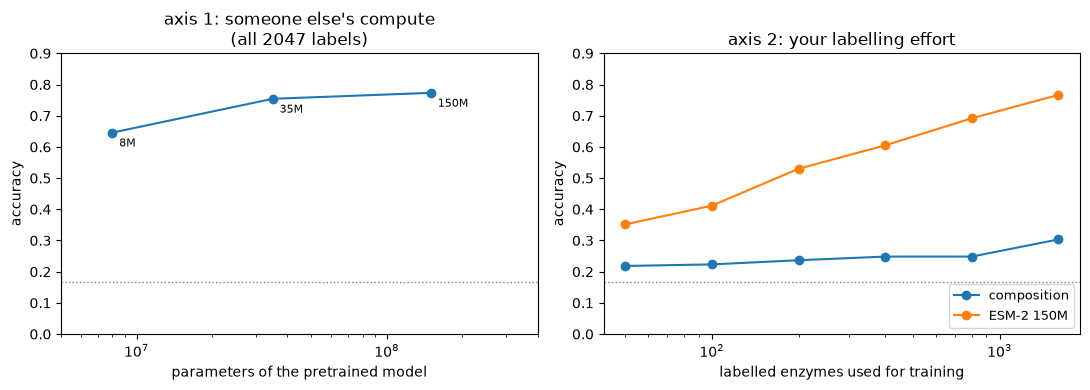

In [ ]:
# @title Support code: the two scaling axes, side by side (figure)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(model_scaling["parameters"], model_scaling["accuracy"], "o-", color="tab:blue")
for name, row in model_scaling.iterrows():
    axes[0].annotate(name.replace("ESM-2 ", ""), (row["parameters"], row["accuracy"]),
                     textcoords="offset points", xytext=(5, -10), fontsize=8)
axes[0].set_xscale("log")
axes[0].set_xlim(5e6, 4e8)
axes[0].set_xlabel("parameters of the pretrained model")
axes[0].set_title("axis 1: someone else's compute\n(all 2047 labels)")

for name, curve in curves.items():
    axes[1].plot(TRAIN_SIZES, curve, "o-", label=name)
axes[1].set_xscale("log")
axes[1].set_xlabel("labelled enzymes used for training")
axes[1].set_title("axis 2: your labelling effort")
axes[1].legend(loc="lower right", fontsize=9)

for ax in axes:
    ax.axhline(1 / 6, color="grey", ls=":", lw=1)
    ax.set_ylim(0, 0.9)
    ax.set_ylabel("accuracy")
plt.tight_layout()

❓ Compare the two panels. With 50 labelled enzymes and ESM-2, how do you do against composition
with *all* 1600? Which axis is cheaper to buy, for you, today?

**Answer.** The embedding trained on **50** enzymes scores **0.352**; composition trained on
**1600** - thirty-two times more labelled data - scores **0.303**. A better representation is
worth more than an order of magnitude of labelling effort on this task. That is the practical
content of "transfer learning": it is a *data-efficiency* multiplier.

Which axis is cheaper depends on who you are. Moving along axis 1 cost Meta thousands of GPU-days,
but you are not paying it - the weights are downloaded, and the embeddings in this repository took
minutes on a laptop. Moving along axis 2 means running assays. For almost every biology group the
pretrained model is nearly free and the labels are the expensive thing, which is exactly why the
slide's caveat - *"only if there is enough training data"* - is about **your** data, not about the
pretraining corpus.

One warning before you quote these curves: the ESM-2 curve has not flattened at 1600, so the
labelling axis is *not* exhausted here. Whatever you read off it is a lower bound.

✏️ **Exercise 2.2.** The left panel has a confound. Bigger ESM-2 models also produce **longer**
embeddings (320, 480, 640 columns), and a linear classifier generally does better with more
columns, knowledge or not. Design a control and run it. *Hint:* `PCA(n_components=100)` inside
the pipeline puts all three on an equal footing.

In [ ]:
from sklearn.decomposition import PCA

for name in SIZES:
    X = esm[f"esm2_{name}"].astype(np.float32)
    fair = make_pipeline(StandardScaler(), PCA(n_components=100, random_state=RNG),
                         LogisticRegression(max_iter=2000))
    print(f"ESM-2 {name:5s} compressed to 100 columns: "
          f"accuracy = {cross_val_score(fair, X, y, cv=random_cv, n_jobs=-1).mean():.3f}")

ESM-2 8M    compressed to 100 columns: accuracy = 0.614


ESM-2 35M   compressed to 100 columns: accuracy = 0.661


ESM-2 150M  compressed to 100 columns: accuracy = 0.639


**Answer.** On an equal number of columns the three models score **0.614, 0.661, 0.639**. The jump
from 8M to 35M survives, shrunk by half. The 35M-to-150M step does not merely vanish, it
**reverses**: the largest model is now worse than the middle one. So a real part of the left panel
was width, not knowledge, and the apparent ordering of the two larger models was an artefact of a
detail of the analysis - which is a sign that there is no solid difference between them to order.

Keep this reflex: whenever a "bigger is better" plot also changes something else (columns,
training time, tokenizer, data), control for that something else before believing the trend.

## Part 3 - The Merck lesson: how you split decides what you believe

In 2012 Merck put 15 activity datasets on Kaggle (slides 66-69): ~11000 descriptors per molecule,
2k-37k measured activities per target. The winning entry was a deep net, and that is the part
everyone remembers. The part worth remembering is in the rules:

> *"For each activity, the training/test set split is done by dates of testing. That is, the
> training set consists of compounds assayed by a certain date, and the test set consists of
> compounds tested after that date. Therefore it is expected that the distribution of descriptors
> will not necessarily be the same between the training and test sets."*
>
> *"We find 'time-split' validation is a much more realistic simulation of true prospective
> prediction in terms of R². We find construction of test sets by random sampling gives R²'s that
> are much too optimistic. That is what makes these data sets more of a challenge."*
> — Sheridan, *J. Chem. Inf. Model.* 2013; Ma et al., doi:10.1021/ci500747n

The reason is medicinal chemistry, not statistics. Chemists do not synthesise molecules at random:
they make a series around a scaffold, test it, and move on. A randomly chosen test compound almost
always has a close analogue in the training set, assayed the same month. A compound made *next*
year does not. Random cross-validation measures interpolation among relatives; prospective
prediction is the question anyone actually asks.

Proteins have the same structure of relatedness, and our enzyme table names it: **family**.
Members of a family share an ancestor, a fold and usually the reaction. Let us measure how much
of the random split is relatives.

In [ ]:
families = enz["family"].values
family_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG)

for label, cv, groups in [("random 5-fold", random_cv, None),
                          ("families held out", family_cv, families)]:
    shared = []
    for i_tr, i_te in cv.split(np.zeros(len(y)), y, groups=groups):
        seen = set(families[i_tr])
        shared.append(np.mean([f in seen for f in families[i_te]]))
    print(f"{label:18s}: {np.mean(shared):.3f} of test proteins have a family-mate in training")

random 5-fold     : 0.618 of test proteins have a family-mate in training
families held out : 0.000 of test proteins have a family-mate in training


Under a random split **62%** of the test proteins have a relative in the training set. That is the
protein version of "assayed the same month". `StratifiedGroupKFold` with `groups=families` keeps
every family entirely on one side, which is our stand-in for the time split.

✏️ **Exercise 3.1.** Cross-validate both representations under both splits and put the four
numbers in one table.

In [ ]:
acc_family = {name: cross_val_score(classifier(), X, y, cv=family_cv,
                                    groups=families, n_jobs=-1).mean()
              for name, X in REPRESENTATIONS}

splits = pd.DataFrame({"random split": acc_random, "families held out": acc_family})
splits["drop"] = splits["random split"] - splits["families held out"]
splits

,random split,families held out,drop
composition,0.291,0.27,0.021
ESM-2 (8M),0.646,0.53,0.116


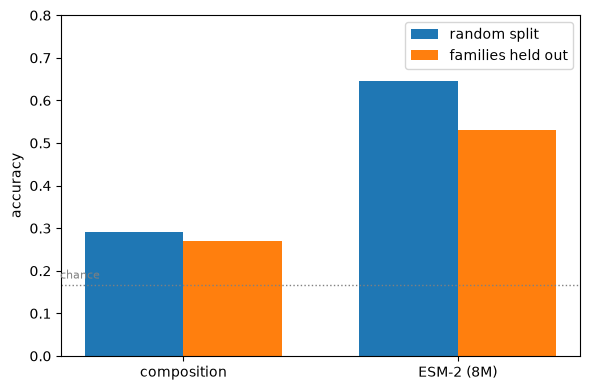

In [ ]:
# @title Support code: random vs grouped split (figure)
x = np.arange(len(splits))
plt.figure(figsize=(6, 4))
plt.bar(x - 0.18, splits["random split"], 0.36, label="random split")
plt.bar(x + 0.18, splits["families held out"], 0.36, label="families held out")
plt.axhline(1 / 6, color="grey", ls=":", lw=1)
plt.text(-0.45, 1 / 6 + 0.015, "chance", color="grey", fontsize=8, ha="left")
plt.xticks(x, splits.index)
plt.ylabel("accuracy")
plt.ylim(0, 0.8)
plt.legend()
plt.tight_layout()

❓ Which representation loses more when relatives are removed? If you had only ever run the random
split, what would you have told your PI?

**Answer.** Composition hardly moves, **0.291 → 0.270**: it had little to lose. ESM-2 falls from
**0.646 to 0.530**, a drop of 0.116 - almost **a fifth** of the random-split score was
"I have seen this family before". Embeddings are extremely good at recognising relatives,
which is precisely why they are used for homology search.

If you had only run the random split you would have promised 65% accuracy on new enzymes and
delivered 53%. Note that the *conclusion* of Part 1 survives intact: the embedding still roughly
doubles composition even with families held out. A pessimistic split does not destroy the result;
it sizes it honestly.

❓ We held the families out of the *classifier*. Were they held out of ESM-2?

**Answer.** No, and this is a limitation we cannot remove with this dataset. ESM-2 was trained on
essentially all known sequences, so it has read these very proteins and their relatives. No
*label* leaked - it never saw an EC number - but "a family the model has never seen" is true only
for the small linear part of our pipeline. A protein family discovered next year would be a harder
test than ours. "Unseen" has degrees, and every score describes the population it was measured on.

### The same lesson on molecules

Can we reproduce the Merck effect on the toxicity data of class 1? Those 908 chemicals carry no
assay dates, so we cannot do a real time split. But the mechanism Merck describes is
**distribution shift between train and test** - *"the distribution of descriptors will not
necessarily be the same"* - and that we can manufacture: sort the molecules by one descriptor,
train on the bottom 75% and test on the top 25%. The test set is then chemistry the model has
never seen, which is what next year's compounds are.

In [ ]:
fish = load_fish()
X_fish = fish[FISH_COLUMNS[:-1]].values
y_fish = fish["LC50"].values

def forest():
    return RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1)

r2_random = cross_val_score(forest(), X_fish, y_fish,
                            cv=KFold(5, shuffle=True, random_state=RNG), scoring="r2").mean()
print(f"random forest, random 5-fold CV: R2 = {r2_random:.3f}\n")
print("correlation of each descriptor with LC50:")
print(fish.corr()["LC50"].drop("LC50").round(3).to_string())

random forest, random 5-fold CV: R2 = 0.604

correlation of each descriptor with LC50:
CIC0      0.292
SM1_Dz    0.411
GATS1i   -0.398
NdsCH     0.172
NdssC     0.172
MLOGP     0.652


✏️ **Exercise 3.2.** Write `descriptor_split(column)`: order the 908 molecules by that descriptor,
train on the lowest 75%, test on the highest 25%, return the test R². Run it for the four
continuous descriptors (`CIC0`, `SM1_Dz`, `GATS1i`, `MLOGP` - the other two are small integer
counts with too many ties to sort meaningfully), for the random forest **and** for an ordinary
linear regression.

In [ ]:
CONTINUOUS = ["CIC0", "SM1_Dz", "GATS1i", "MLOGP"]

def descriptor_split(column):
    """Indices of the lowest 75% and the highest 25% of `column`."""
    order = np.argsort(fish[column].values, kind="stable")
    cut = int(0.75 * len(fish))
    return order[:cut], order[cut:]

rows = []
for name, make in [("linear", LinearRegression), ("forest", forest)]:
    row = {"model": name,
           "random 5-fold": cross_val_score(make(), X_fish, y_fish,
                                            cv=KFold(5, shuffle=True, random_state=RNG),
                                            scoring="r2").mean()}
    for column in CONTINUOUS:
        i_tr, i_te = descriptor_split(column)
        fitted = make().fit(X_fish[i_tr], y_fish[i_tr])
        row[f"split on {column}"] = r2_score(y_fish[i_te], fitted.predict(X_fish[i_te]))
    rows.append(row)
shift = pd.DataFrame(rows).set_index("model")
shift

,random 5-fold,split on CIC0,split on SM1_Dz,split on GATS1i,split on MLOGP
model,,,,,
linear,0.557,0.135,0.400,0.530,0.089
forest,0.604,0.289,0.163,0.465,0.044


MLOGP   : train mean 1.50, test mean 3.93
LC50    : train mean 3.62, test mean 5.41, largest value in training 9.61, in test 9.35
linear  : largest prediction on the test set 7.93
forest  : largest prediction on the test set 6.28


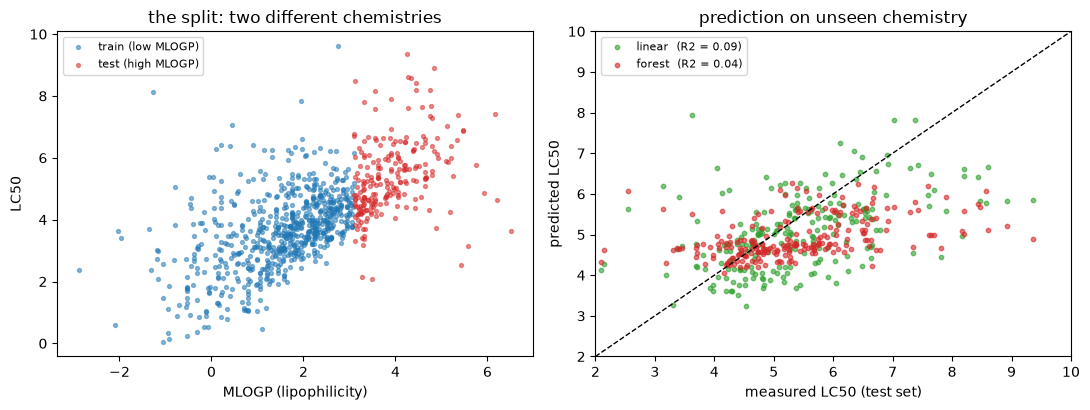

In [ ]:
# @title Support code: predicted vs measured under the MLOGP split (figure)
i_tr, i_te = descriptor_split("MLOGP")
print(f"MLOGP   : train mean {fish['MLOGP'].values[i_tr].mean():.2f}, "
      f"test mean {fish['MLOGP'].values[i_te].mean():.2f}")
print(f"LC50    : train mean {y_fish[i_tr].mean():.2f}, test mean {y_fish[i_te].mean():.2f}, "
      f"largest value in training {y_fish[i_tr].max():.2f}, in test {y_fish[i_te].max():.2f}")
for name, make in [("linear", LinearRegression), ("forest", forest)]:
    pred = make().fit(X_fish[i_tr], y_fish[i_tr]).predict(X_fish[i_te])
    print(f"{name:8s}: largest prediction on the test set {pred.max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].scatter(fish["MLOGP"].values[i_tr], y_fish[i_tr], s=8, alpha=0.5, label="train (low MLOGP)")
axes[0].scatter(fish["MLOGP"].values[i_te], y_fish[i_te], s=8, alpha=0.5, color="tab:red",
                label="test (high MLOGP)")
axes[0].set_xlabel("MLOGP (lipophilicity)")
axes[0].set_ylabel("LC50")
axes[0].set_title("the split: two different chemistries")
axes[0].legend(fontsize=8)

for name, make, colour in [("linear", LinearRegression, "tab:green"), ("forest", forest, "tab:red")]:
    pred = make().fit(X_fish[i_tr], y_fish[i_tr]).predict(X_fish[i_te])
    axes[1].scatter(y_fish[i_te], pred, s=10, alpha=0.6, color=colour,
                    label=f"{name}  (R2 = {r2_score(y_fish[i_te], pred):.2f})")
lims = [2, 10]
axes[1].plot(lims, lims, "k--", lw=1)
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_xlabel("measured LC50 (test set)")
axes[1].set_ylabel("predicted LC50")
axes[1].set_title("prediction on unseen chemistry")
axes[1].legend(fontsize=8)
plt.tight_layout()

❓ Three things to read off the table and the figure. (i) How large is the optimism of the random
split? (ii) Does the *ranking of the two models* survive the change of split? (iii) Look at the
right-hand panel: what shape is the error?

**Answer.**

(i) **Huge.** The forest scores **0.604** by random 5-fold and **0.044** when the lipophilic
quarter of the chemical space is held out. Same data, same model, same code; the only thing that
changed is which molecules counted as "test". Every one of the four descriptor splits is worse
than random, from 0.465 down to 0.044. Merck's *"much too optimistic"* is not a rhetorical
flourish.

(ii) **No.** On the random split the forest beats the linear model (0.604 vs 0.557), and that is
the comparison a paper would report. Split on `SM1_Dz` and the ranking reverses hard - linear
0.400, forest 0.163 - and on `MLOGP` both are near zero. The split does not just rescale the
scores, it can change which method you would publish.

(iii) **Systematic, not random.** The test molecules are more lipophilic and therefore more toxic
(mean LC50 5.41 against 3.62 in training), and both models under-predict: the points sit below the
diagonal. The forest is worse because a tree can only ever average training targets, so its
largest prediction anywhere on the test set is **6.28** while measured test values go up to
**9.35** - **a random forest cannot extrapolate past the targets it was shown**. The linear model
at least keeps extending its trend (up to 7.93), which is why it loses less here. Flexible models are the ones that pay the most for distribution shift, which is
uncomfortable, because flexible models are the ones we are selling.

❓ Someone objects: "sorting by MLOGP is a worst case you engineered; a time split would be
gentler." Are they right, and does it matter?

**Answer.** Partly right. `MLOGP` is the single descriptor most correlated with LC50 (r = 0.65), so
splitting on it is close to the nastiest shift available, whereas a real time split shifts the
descriptor distribution only as fast as a project's chemistry drifts. But Merck measured the
gentler, realistic version and still found random sampling *"much too optimistic"*. The engineered
split is a magnifying glass on a real effect, not an invention. The practical rule is the same
either way: **choose the split that imitates how the model will be used**, before you look at any
score. Time, scaffold, family, patient, hospital, batch - the grouping variable is domain
knowledge, not a hyperparameter.

## Part 4 - Where do the data come from?

Slide 72 opens with a question that no accuracy number can answer:

> *Where do the data come from? Database errors contain biases. They reflect on results, yet they
> are hidden.*

This part has almost no modelling in it. You will look at the provenance of the two datasets you
have been using for three classes, and write down - in words - what a model trained on them may
and may not be used for. This is now a regulatory requirement in several jurisdictions (OECD QSAR
validation principles ask for a defined "applicability domain"; the EU AI Act asks for
documentation of training data), and it is the part students most often skip.

In [ ]:
print("ENZYMES - organism x EC class")
print(pd.crosstab(enz["organism"], enz["ec_name"], margins=True, margins_name="total"))
print()
print("sequence length:", enz["length"].describe()[["min", "50%", "max"]].to_dict())

sizes = enz["family"].value_counts()
print(f"\n{len(sizes)} families; largest has {sizes.max()} members; "
      f"{(sizes == 1).sum()} families have a single member "
      f"({(sizes == 1).sum() / len(enz):.1%} of all proteins)")
mixed = enz.groupby("family")["ec_class"].nunique()
print(f"{(mixed > 1).sum()} families contain more than one EC class")

ENZYMES - organism x EC class
ec_name                   Hydrolase  Isomerase  Ligase  Lyase  Oxidoreductase  \
organism                                                                        
Arabidopsis thaliana            121        100      67    118             128   
Bacillus subtilis                37         55      63     63              53   
Escherichia coli                 32         73      64     65              49   
Homo sapiens                    120         72      58     57              88   
Saccharomyces cerevisiae         40         50      45     47              32   
total                           350        350     297    350             350   

ec_name                   Transferase  total  
organism                                      
Arabidopsis thaliana              149    683  
Bacillus subtilis                  32    303  
Escherichia coli                   39    322  
Homo sapiens                       98    493  
Saccharomyces cerevisiae           32  

In [ ]:
print("FISH TOXICITY - descriptor ranges (the chemical space actually covered)")
print(fish.describe().loc[["min", "25%", "50%", "75%", "max"]])

FISH TOXICITY - descriptor ranges (the chemical space actually covered)
      CIC0  SM1_Dz  GATS1i  NdsCH  NdssC  MLOGP   LC50
min  0.667   0.000   0.396    0.0    0.0 -2.884  0.053
25%  2.347   0.223   0.951    0.0    0.0  1.209  3.152
50%  2.934   0.570   1.240    0.0    0.0  2.127  3.987
75%  3.407   0.893   1.562    0.0    1.0  3.105  4.907
max  5.926   2.171   2.920    4.0    6.0  6.515  9.612


✏️ **Exercise 4.1.** Using only what is printed above and what you know about how the tables were
made, write a short "limitations" paragraph for each dataset: **who is in it, who is missing, and
what would make a prediction untrustworthy**. Five lines each. Compare with your neighbour before
reading on.

**Answer (one acceptable version).**

**Enzymes.** The table is 2047 *reviewed* Swiss-Prot entries from five laboratory organisms:
*Arabidopsis* (683), human (493), *E. coli* (322), *B. subtilis* (303), yeast (246). That is the
first bias and it is a *curation* bias, not a sampling one - Swiss-Prot is hand-annotated, so it
over-represents what people chose to study, and the model organisms are the proteins with
experimental evidence. Missing: everything unreviewed (TrEMBL is ~1000x larger and mostly
machine-annotated), archaea, viruses, every uncultured organism, multi-domain enzymes with several
EC numbers, and anything outside 81-993 residues. The classes were balanced to ~350 each **by us**
during data preparation, so the class frequencies in the file are an artefact of the exercise and
*not* the frequencies in biology; a model fitted here has the wrong prior for any real screen.
A third of the proteins sit in a family of their own, which is why the grouped split of Part 3
is both possible and severe. A prediction would be untrustworthy for a protein from a
non-model clade, for a promiscuous or moonlighting enzyme, and for anything whose family is not
represented - and remember that the EC labels themselves are human annotations, many inferred by
similarity, i.e. partly the output of a model of the same kind we are training.

**Fish toxicity.** 908 chemicals with a 96-hour LC50 on *one* species, the fathead minnow,
assembled by Cassotti et al. from regulatory data (ECHA/REACH-style dossiers) and deposited at UCI.
Who is in it: industrial organic chemicals with MLOGP from -2.9 to 6.5, i.e. mostly small, mostly
neutral, mostly lipophilic enough to be interesting to a regulator. Missing: metals, salts,
ionisable and very polar compounds, mixtures, everything too insoluble to test, and - importantly -
chemicals that were never submitted for registration. The endpoint is acute lethality in one fish
over four days: it says nothing about chronic effects, bioaccumulation, endocrine disruption, or
other species. There are no assay dates and no molecular structures in the file, only six
descriptors, so we cannot audit for near-duplicates or scaffold series; Part 3 showed that this
matters. A prediction would be untrustworthy outside the descriptor ranges printed above - which
is exactly the "applicability domain" that OECD asks QSAR submissions to state, and exactly what
Part 3's MLOGP split simulated.

❓ Slide 59 says *"black boxes do not empower discovery"*, and slide 72 warns that database biases
*"reflect on results, yet they are hidden"*. Which of the two is actually the bigger problem for
the models you built today?

**Answer.** Defensible either way, but argue it. The *black box* complaint is mild here: our
classifier is a logistic regression, you can read its coefficients - and that buys you nothing,
because the 320 inputs are ESM-2 coordinates with no meaning. Interpretability was not lost in the
classifier, it was lost upstream in the representation, and that is where it is usually lost.
The *data* complaint is sharper and more actionable: the organism mix, the artificial class
balance, the curation bias toward studied proteins and registered chemicals are all invisible in
an accuracy number, none of them are fixed by a better model, and every one of them changes what
the number means. Both complaints share a remedy that slide 61 names: **open models and open
data**. You can run this audit at all only because Swiss-Prot, UCI and the ESM-2 weights are
public. For a proprietary model trained on a proprietary corpus, Part 3 and Part 4 of this
notebook are simply impossible to perform.

## Part 5 (optional) - Generating peptides, and judging the result honestly

Slide 54 shows peptide generation with a recurrent network and slides 55-56 molecular generation
through the latent space of a variational autoencoder. The shared recipe: train a network to
reproduce a distribution of sequences, then sample from it and hope the samples are new and good.

We can do the recurrent half in a couple of minutes. The training set is the **1200 signal
peptides** of the targeting dataset (class 2): the N-terminal address labels that send a protein
into the secretory pathway. A signal peptide has a loose but real grammar - a short positively
charged start, a hydrophobic core, a small-residue cleavage site - and no fixed motif, which makes
it a fair target for a generative model.

The network reads the peptide one residue at a time and predicts the next one. That is all. To
generate, you feed it a start token and sample residue by residue from its predicted
distribution.

In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(RNG)

tp = load_targeting()
LENGTH = 30                                        # residues we model
signal_peptides = [s[:LENGTH] for s in tp.loc[tp["label"] == "SP", "nterm"]]
print(len(signal_peptides), "signal peptides, e.g.", signal_peptides[0])

aa_index = {a: i for i, a in enumerate(AA)}
START = 20                                         # a 21st token meaning "begin"
tokens = torch.tensor([[START] + [aa_index[a] for a in s] for s in signal_peptides])
print("token tensor:", tuple(tokens.shape))

1200 signal peptides, e.g. MVSSFFMASTLLAISSCFNSSISRAKGYND
token tensor: (1200, 31)


In [ ]:
class PeptideGenerator(nn.Module):
    """Character-level GRU: given the residues so far, score the next residue."""

    def __init__(self, hidden=64):
        super().__init__()
        self.embed = nn.Embedding(21, 16)          # 20 residues + START
        self.gru = nn.GRU(16, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 20)

    def forward(self, x, state=None):
        out, state = self.gru(self.embed(x), state)
        return self.head(out), state


torch.manual_seed(RNG)
generator = PeptideGenerator()
print(sum(p.numel() for p in generator.parameters()), "trainable parameters")

inputs, targets = tokens[:, :-1], tokens[:, 1:]    # predict residue t+1 from residues 1..t
optimiser = torch.optim.Adam(generator.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(1, 41):
    order = torch.randperm(len(inputs))
    total = 0.0
    for start in range(0, len(order), 64):
        batch = order[start:start + 64]
        scores, _ = generator(inputs[batch])
        loss = loss_fn(scores.reshape(-1, 20), targets[batch].reshape(-1))
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
        total += loss.item() * len(batch)
    if epoch % 10 == 0:
        print(f"epoch {epoch:3d}  mean loss = {total / len(inputs):.3f}  "
              f"(a uniform guess would give {np.log(20):.3f})")

17380 trainable parameters


epoch  10  mean loss = 2.446  (a uniform guess would give 2.996)


epoch  20  mean loss = 2.354  (a uniform guess would give 2.996)


epoch  30  mean loss = 2.273  (a uniform guess would give 2.996)


epoch  40  mean loss = 2.213  (a uniform guess would give 2.996)


In [ ]:
@torch.no_grad()
def sample_peptides(n=6, temperature=1.0, seed=RNG):
    """Sample n peptides residue by residue from the trained network."""
    rng = torch.Generator().manual_seed(seed)
    x = torch.full((n, 1), START)
    state, drawn = None, []
    for _ in range(LENGTH):
        scores, state = generator(x, state)
        probs = torch.softmax(scores[:, -1] / temperature, dim=-1)
        x = torch.multinomial(probs, 1, generator=rng)
        drawn.append(x)
    return ["".join(AA[i] for i in row) for row in torch.cat(drawn, dim=1).tolist()]


print("generated:")
for s in sample_peptides(6):
    print(" ", s)
print("\nreal, for comparison:")
for s in signal_peptides[:6]:
    print(" ", s)

generated:
  MKNTLIKLFLSSLVFIFSANVNGNLFAKLQ
  MAARFIFLSVIIFTSVIFSLATDAPSGNVF
  MKFHFACAVVLVECVSSGRYIALTNKTNVH
  MAKTILLIPSALSLTETTFSITLDTRAAIT
  MSLSLIMLMAILFFISSQAQLREPEKNNRN
  MARFLPVLTLLVLLIVKEGIRIRVCAKTCL

real, for comparison:
  MVSSFFMASTLLAISSCFNSSISRAKGYND
  MAWTPLLLLLLSHCTGSLSQPVLTQPPSSS
  MAWATLLLPLLNLYTGSVASYELTQLPSVS
  MAWIPLLLPLLTLCTGSEASYELTQPPSVS
  MPLVVAVIFFSLWVFALGQLEQPEISISRP
  MLLLLLLLGPGSGLGAVVSQHPSRVICKSG


They look right: almost all start with methionine, most have a hydrophobic stretch in positions
5-20, several end in a small-residue cleavage-site pattern. **This is where papers stop and where
you should not.** "Looks plausible to me" is not a result. Two cheap checks:

1. does something other than your eye call them signal peptides?
2. is the network inventing, or reciting its training set?

✏️ **Exercise 5.1.** Train a composition-based SP-vs-rest logistic regression on the targeting
data (first 30 residues), and apply it to 200 generated peptides, 200 real signal peptides and 200
`other` N-termini. Then compute, for each generated peptide, its highest percentage identity to
any training peptide, and compare with the same statistic among real signal peptides.

In [ ]:
X_tp = np.vstack([aa_composition(s[:LENGTH]) for s in tp["nterm"]])
is_sp = (tp["label"] == "SP").values
detector_cv = cross_val_score(LogisticRegression(max_iter=2000), X_tp, is_sp, cv=5).mean()
detector = LogisticRegression(max_iter=2000).fit(X_tp, is_sp)
print(f"the SP detector itself is only {detector_cv:.3f} accurate in cross-validation\n")

generated = sample_peptides(200, seed=1)
real_sp = list(np.random.default_rng(RNG).choice(signal_peptides, 200, replace=False))
other = [s[:LENGTH] for s in tp.loc[tp["label"] == "other", "nterm"]][:200]

for label, peptides in [("generated", generated), ("real SP", real_sp), ("real 'other'", other)]:
    called = detector.predict(np.vstack([aa_composition(s) for s in peptides])).mean()
    print(f"{label:14s}: {called:.1%} called 'signal peptide'")

def max_identity(peptide, pool):
    return max(sum(a == b for a, b in zip(peptide, other_pep)) / LENGTH
               for other_pep in pool if other_pep != peptide)

print(f"\nhighest identity to a training peptide:")
print(f"  generated      : {np.mean([max_identity(s, signal_peptides) for s in generated[:50]]):.3f}")
print(f"  real SP vs rest: {np.mean([max_identity(s, signal_peptides) for s in real_sp[:50]]):.3f}")

the SP detector itself is only 0.880 accurate in cross-validation

generated     : 73.0% called 'signal peptide'
real SP       : 81.5% called 'signal peptide'
real 'other'  : 3.5% called 'signal peptide'

highest identity to a training peptide:
  generated      : 0.323


  real SP vs rest: 0.378

❓ Has the network learned to write signal peptides?

**Answer.** It has learned *something*, and the honest statement of what is narrower than the
samples suggest.

What we can claim: the detector calls **73%** of the generated peptides signal peptides, against
**81.5%** of real ones and **3.5%** of real `other` N-termini. The generated peptides land near
the real distribution and nowhere near the negative one. And they are not memorised: a generated
peptide shares on average **0.323** of its residues with its closest training peptide, slightly
*less* than one real signal peptide shares with the next-closest real one (**0.378**). The model
interpolates the grammar rather than reciting examples.

What we cannot claim: the judge is a 30-residue composition model whose own cross-validated
accuracy is **0.880**, and it ignores the order of residues entirely - the one thing a signal
peptide depends on. Passing it is a necessary condition, not evidence of function. A real
assessment needs SignalP or a structural check, and ultimately an experiment: express the fusion
and see whether the protein is secreted. Nothing here tells you whether a single one of these
peptides would work in a cell.

This gap - between a generative model that produces things *shaped* like the training data and a
claim that they *work* - is the main thing to carry away from slides 54-56. The VAE latent space
is prettier and the same caution applies: the decoder will happily hand you a molecule that is
unsynthesisable, unstable, or merely a copy of something in the training set with one atom moved.
Generation is cheap; the filter and the assay are the expensive parts, and they are where the
science is.

## Summary

* **Transfer learning.** The same logistic regression on the same 2047 enzymes: **0.291** with
  amino-acid composition, **0.646** with an ESM-2 embedding. The classifier did not get smarter;
  the representation did. Concatenating the hand-crafted descriptors on top changes nothing
  (**0.644**).
* **Two axes of scaling.** Along the model axis, 8M → 35M → 150M parameters gives 0.646 → 0.754 →
  0.773: real, but already bending, and the second step does not survive a control for embedding
  width. Along the label axis, the embedding with **50** labelled enzymes (0.352) beats
  composition with **1600** (0.303). For you, the pretrained model is nearly free and labels are
  not.
* **The split decides what you believe.** 62% of test proteins have a family-mate in training under
  a random split; holding families out costs the embedding 0.646 → 0.530. On the fish toxicity
  data, a random forest scores R² = **0.604** by random 5-fold and **0.044** when the lipophilic
  quarter is held out, and the forest-vs-linear ranking reverses under some splits. This is
  Merck's time split in miniature: *"random sampling gives R²'s that are much too optimistic"*.
  Choose the split that imitates deployment, before looking at any score.
* **Provenance.** Five model organisms, a class balance we imposed ourselves, a single fish
  species, chemicals someone chose to register. None of this is visible in an accuracy, none of it
  is fixed by a bigger model, and you could only check it because the data and the weights are
  open.
* **Generation.** A 17k-parameter GRU writes peptides that a weak detector accepts at nearly the
  rate of real ones and that are not copies. That is a distributional claim, not a functional one.

## References and data sources

**Data**

* `enzymes.tsv`, `targeting.tsv`: reviewed entries of UniProtKB/Swiss-Prot (UniProt Consortium
  2023), downloaded with the UniProt REST API on 2026-11-10 from human, *E. coli* K-12, yeast,
  *Arabidopsis thaliana* and *Bacillus subtilis*, then balanced across classes. Swiss-Prot changes
  at every release, so the committed TSVs are the reference. See `course/README.md` and
  `course/data_prep/`.
* `enzymes_esm2.npz`: mean-pooled ESM-2 embeddings of those same proteins at three model sizes,
  computed once with `course/data_prep/make_esm2_embeddings.py`.
* `qsar_fish_toxicity.csv`: *Pimephales promelas* 96 h LC50 for 908 chemicals, UCI Machine
  Learning Repository, from Cassotti M, Ballabio D, Todeschini R, Consonni V (2015). A similarity-
  based QSAR model for predicting acute toxicity towards the fathead minnow. *SAR and QSAR in
  Environmental Research* 26:217-243. [doi:10.1080/1062936X.2015.1018938](https://doi.org/10.1080/1062936X.2015.1018938)

**Papers behind the slides**

* Ma J, Sheridan RP, Liaw A, Dahl GE, Svetnik V (2015). Deep neural nets as a method for
  quantitative structure-activity relationships. *J. Chem. Inf. Model.* 55:263-274.
  [doi:10.1021/ci500747n](https://doi.org/10.1021/ci500747n) — the Merck Kaggle challenge
  (slides 66-69) and the source of the "much too optimistic" conclusion.
* Sheridan RP (2013). Time-split cross-validation as a method for estimating the goodness of
  prospective prediction. *J. Chem. Inf. Model.* 53:783-790.
  [doi:10.1021/ci400084k](https://doi.org/10.1021/ci400084k) — the time split itself, measured.
* Cai C, Guo P, Zhou Y, et al. (2019). Deep learning-based prediction of drug-induced
  cardiotoxicity. *J. Chem. Inf. Model.* 59:1073-1084.
  [doi:10.1021/acs.jcim.8b00769](https://doi.org/10.1021/acs.jcim.8b00769) — deephERG
  (slides 49-50), 185 MOE descriptors + 100 Mol2vec features.
* Jaeger S, Fulle S, Turk S (2018). Mol2vec: unsupervised machine learning approach with chemical
  intuition. *J. Chem. Inf. Model.* 58:27-35.
  [doi:10.1021/acs.jcim.7b00616](https://doi.org/10.1021/acs.jcim.7b00616)
* Lin Z, Akin H, Rao R, et al. (2023). Evolutionary-scale prediction of atomic-level protein
  structure with a language model. *Science* 379:1123-1130.
  [doi:10.1126/science.ade2574](https://doi.org/10.1126/science.ade2574) — ESM-2 (slide 44).
* Gómez-Bombarelli R, Wei JN, Duvenaud D, et al. (2018). Automatic chemical design using a
  data-driven continuous representation of molecules. *ACS Central Science* 4:268-276.
  [doi:10.1021/acscentsci.7b00572](https://doi.org/10.1021/acscentsci.7b00572) — the molecular VAE
  and its latent space (slides 55-56).
* Müller AT, Hiss JA, Schneider G (2018). Recurrent neural network model for constructive peptide
  design. *J. Chem. Inf. Model.* 58:472-479.
  [doi:10.1021/acs.jcim.7b00414](https://doi.org/10.1021/acs.jcim.7b00414) — peptide generation
  with an RNN (slide 54).
* Teufel F, Almagro Armenteros JJ, Johansen AR, et al. (2022). SignalP 6.0 predicts all five types
  of signal peptides using protein language models. *Nature Biotechnology* 40:1023-1025.
  [doi:10.1038/s41587-021-01156-3](https://doi.org/10.1038/s41587-021-01156-3) — what a real
  judge of Part 5 would look like.

**On splits, leakage and provenance**

* Kapoor S, Narayanan A (2023). Leakage and the reproducibility crisis in machine-learning-based
  science. *Patterns* 4:100804.
  [doi:10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804)
* Gebru T, Morgenstern J, Vecchione B, et al. (2021). Datasheets for datasets. *Communications of
  the ACM* 64:86-92. [doi:10.1145/3458723](https://doi.org/10.1145/3458723) — a template for the
  audit of Part 4.
* OECD (2014). Guidance document on the validation of (Q)SAR models, ENV/JM/MONO(2007)2 — the
  origin of "defined applicability domain".